In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import metrics
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_error
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing


import warnings

warnings.simplefilter(action='ignore', category=FutureWarning)

In [2]:
df = pd.read_csv('nitm18442004.csv')
print(df.shape)
df.head()

(1932, 1)


,x
0,4.5
1,2.4
2,4.8
3,9.1
4,10.9


In [3]:
import calendar
dates = []

for year in range(1844, 2005):
    for month in range(1, 13):
        last_day = calendar.monthrange(year, month)[1]
        date = f"{year}-{month}-{last_day}"
        dates.append(date)

In [4]:
df['Date'] = dates
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date',inplace= True)


In [6]:
df

,x
Date,
1844-01-31,4.5
1844-02-29,2.4
1844-03-31,4.8
1844-04-30,9.1
1844-05-31,10.9
...,...
2004-08-31,15.4
2004-09-30,13.2
2004-10-31,8.6


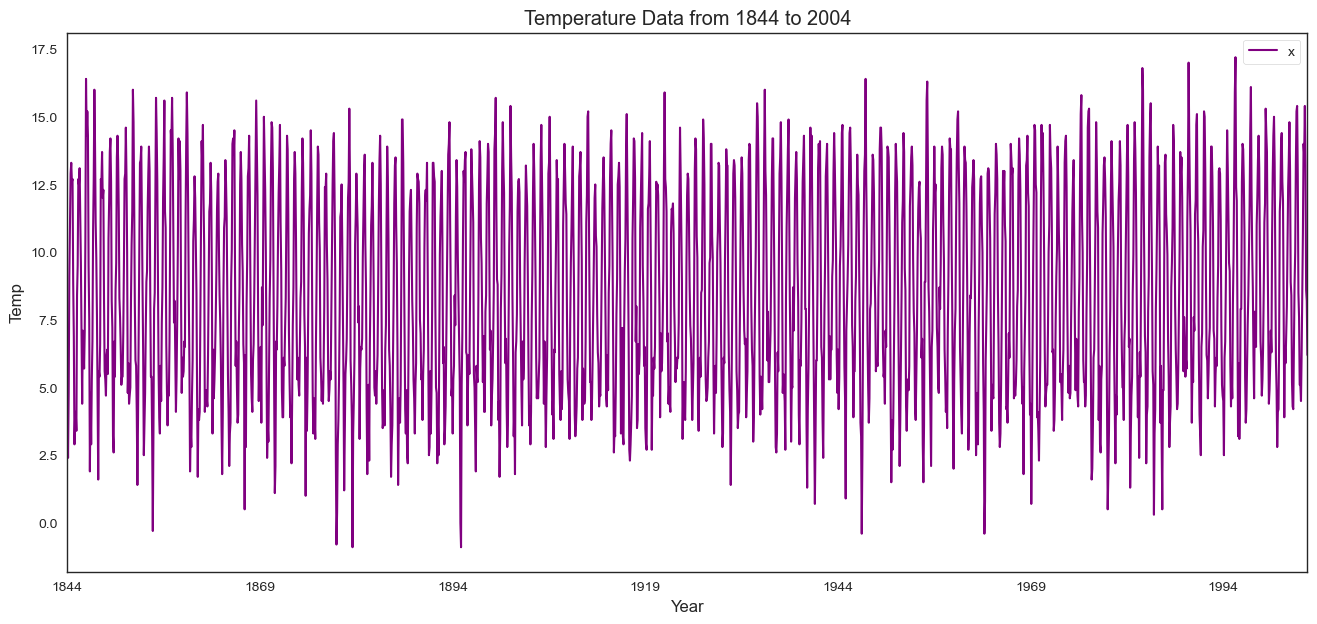

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style('white')

a = '1844-1-31'
b = '2004-12-31'

df.loc[a:b].plot(figsize=(16, 7), color='purple')
plt.title('Temperature Data from 1844 to 2004')
plt.xlabel('Year')
plt.ylabel('Temp')
plt.show()

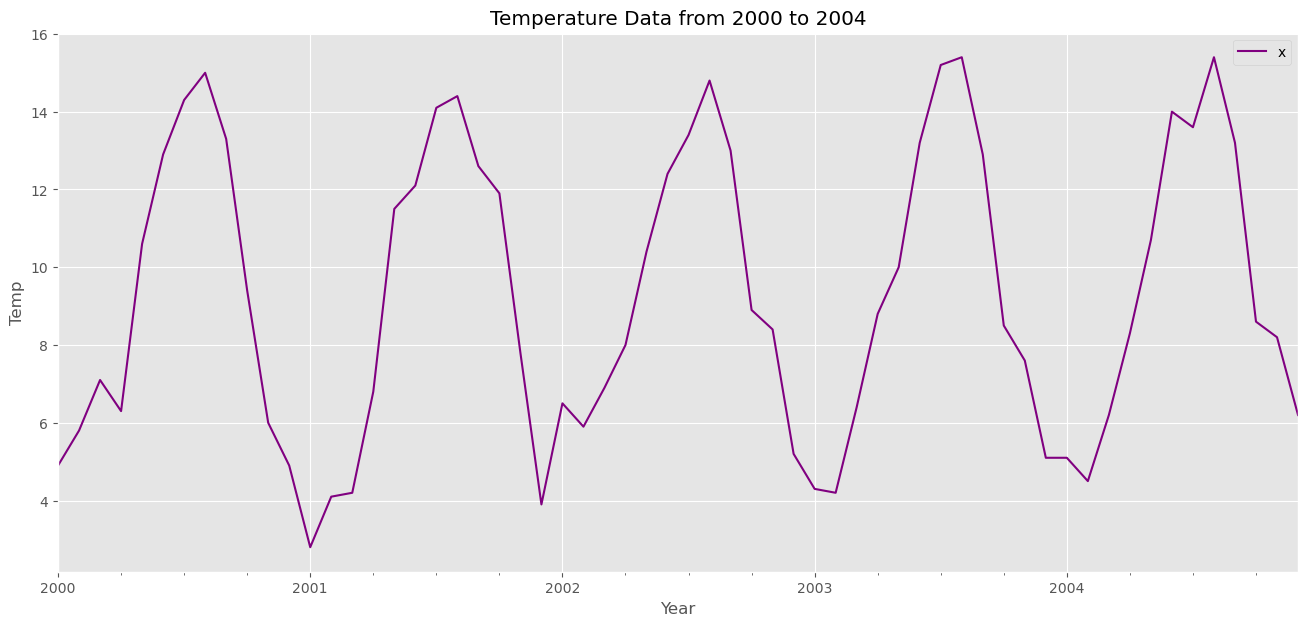

In [26]:
plt.style.use('default')
plt.style.use('ggplot')

a = '2000-1-31'
b = '2004-12-31'

df.loc[a:b].plot(figsize=(16, 7), color='purple')
plt.title('Temperature Data from 2000 to 2004')
plt.xlabel('Year')
plt.ylabel('Temp')
plt.show()

In [27]:
# Check the stationarity of the time series using the Augmented Dickey-Fuller (ADF) test
from statsmodels.tsa.stattools import adfuller
result = adfuller(df['x'])
print(f'ADF Statistic: {result[0]}')
print(f'p-value: {result[1]}')
print('Critical Values:')
for key, value in result[4].items():
    print(f'   {key}: {value}')

ADF Statistic: -5.000623974120459
p-value: 2.2130135390222654e-05
Critical Values:
   1%: -3.433787340386774
   5%: -2.8630583903440656
   10%: -2.567578333092222


In [28]:
from sklearn.model_selection import train_test_split

# split the dataset into training and test sets
train_data, test_data = train_test_split(df, test_size=12, shuffle=False)

In [29]:
test_data

,x
Date,
2004-01-31,5.1
2004-02-29,4.5
2004-03-31,6.2
2004-04-30,8.3
2004-05-31,10.7
2004-06-30,14.0
2004-07-31,13.6
2004-08-31,15.4
2004-09-30,13.2


C:\Users\Lenovo\anaconda3\lib\site-packages\statsmodels\tsa\base\tsa_model.py:471: ValueWarning: No frequency information was provided, so inferred frequency M will be used.
  self._init_dates(dates, freq)
C:\Users\Lenovo\anaconda3\lib\site-packages\statsmodels\tsa\base\tsa_model.py:471: ValueWarning: No frequency information was provided, so inferred frequency M will be used.
  self._init_dates(dates, freq)
C:\Users\Lenovo\anaconda3\lib\site-packages\statsmodels\tsa\base\tsa_model.py:471: ValueWarning: No frequency information was provided, so inferred frequency M will be used.
  self._init_dates(dates, freq)
C:\Users\Lenovo\anaconda3\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
C:\Users\Lenovo\anaconda3\lib\site-packages\statsmodels\base\model.py:604: ConvergenceWarning: Maximum Likelihood optimization fai

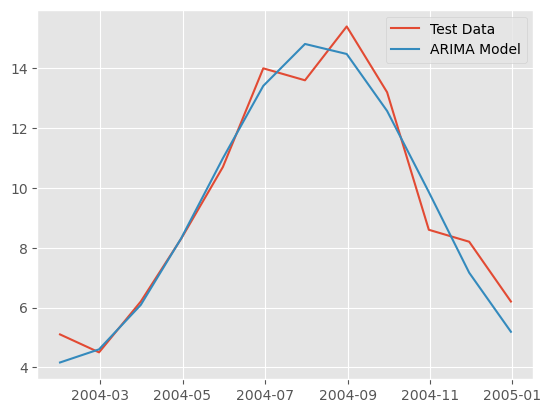

In [33]:
# Fit an ARIMA model to the training set
model = ARIMA(train_data['x'], order=(12, 1, 1))
results = model.fit()

# Make predictions on the testing set
predictions = results.predict(start=test_data.index[0], end=test_data.index[-1], typ='levels')

# Plot the results
#plt.plot(train_data['x'], label='Training Data')
plt.plot(test_data['x'], label='Test Data')
plt.plot(predictions, label='ARIMA Model')
plt.legend()
plt.show()

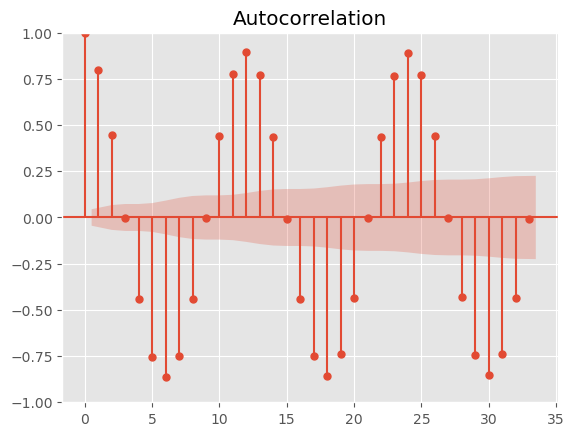

In [34]:

# Plot the ACF
plot_acf(df['x'])
plt.show()

C:\Users\Lenovo\anaconda3\lib\site-packages\statsmodels\graphics\tsaplots.py:348: FutureWarning: The default method 'yw' can produce PACF values outside of the [-1,1] interval. After 0.13, the default will change tounadjusted Yule-Walker ('ywm'). You can use this method now by setting method='ywm'.
  warnings.warn(


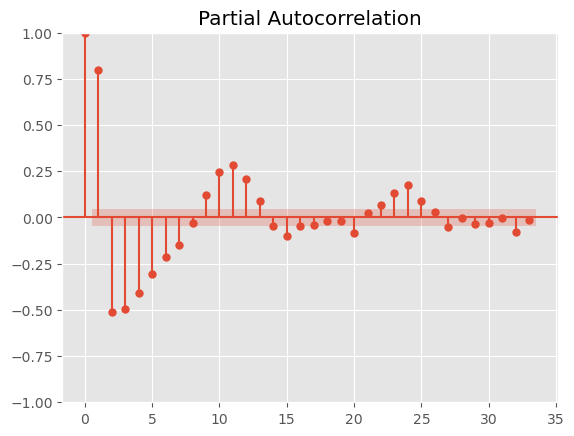

In [15]:

# Plot the ACF
plot_pacf(df['x'])
plt.show()

In [37]:
# Fit the exponential smoothing model to the training data
model = ExponentialSmoothing(train_data['x'],  seasonal_periods=12, trend='add', seasonal='add').fit()

# Make predictions for the test set
predictions = model.predict(start=test_data.index[0], end=test_data.index[-1])

# Calculate the error metrics
mse = ((predictions - test_data['x']) ** 2).mean()
rmse = np.sqrt(mse)
mae = (abs(predictions - test_data['x'])).mean()

# Print the error metrics
print('MSE: ', mse)
print('RMSE: ', rmse)
print('MAE: ', mae)


C:\Users\Lenovo\anaconda3\lib\site-packages\statsmodels\tsa\base\tsa_model.py:471: ValueWarning: No frequency information was provided, so inferred frequency M will be used.
  self._init_dates(dates, freq)


MSE:  0.6183767984558816
RMSE:  0.78636937787269
MAE:  0.6954856772225945


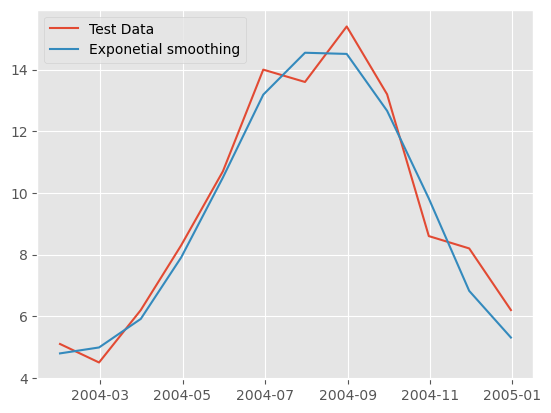

In [17]:
plt.plot(test_data['x'], label='Test Data')
plt.plot(predictions, label='Exponetial smoothing')
plt.legend()
plt.show()

In [18]:
# Define the Naive Method
def naive_method(series):
    return series.shift(1)

# Apply the Naive Method to the test set
naive_pred = naive_method(test_data['x'])



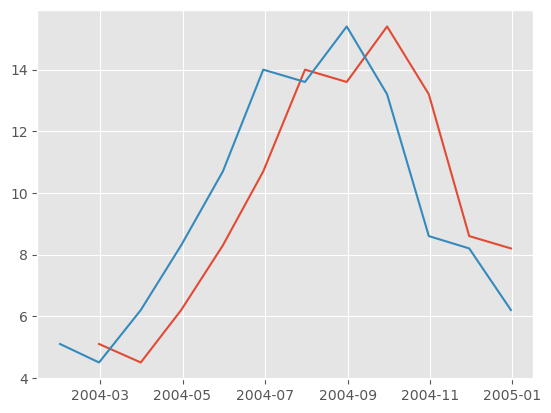

In [19]:
plt.plot(naive_pred)
plt.plot(test_data)

In [38]:
df


,x
Date,
1844-01-31,4.5
1844-02-29,2.4
1844-03-31,4.8
1844-04-30,9.1
1844-05-31,10.9
...,...
2004-08-31,15.4
2004-09-30,13.2
2004-10-31,8.6


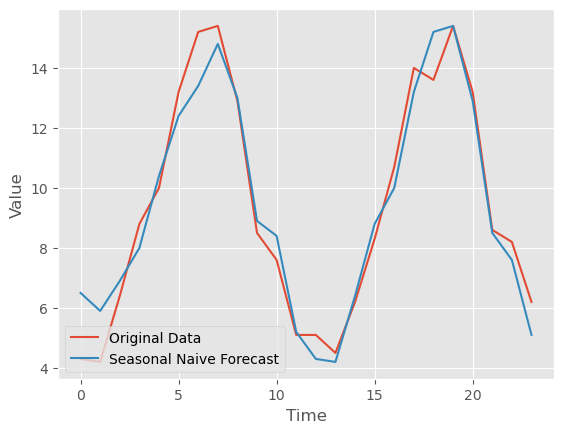

In [53]:


def seasonal_naive_forecast(data, seasonal_period):
    forecast = np.roll(data, seasonal_period)
    return forecast

# Example usage:
# Assuming 'data' is your time series data and 'seasonal_period' is the length of the seasonal pattern

# Provide your actual time series data here
data = df['x']
# Specify the length of the seasonal pattern
seasonal_period = 12

# Generate the seasonal naive forecast
forecast = seasonal_naive_forecast(data, seasonal_period)

# Plot the last 24 points of the original data and the forecast
last_24_data = data[-24:]
last_24_forecast = forecast[-24:]

plt.plot(range(len(last_24_data)), last_24_data, label='Original Data')
plt.plot(range(len(last_24_forecast)), last_24_forecast, label='Seasonal Naive Forecast')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.show()
